# Task 3 — person, place, and object in context

30 images each, with the words that state the relation. Boxes are drawn when the dataset has them.

- **VisualNews** — news photo and caption (a person at an event or a place)
- **Visual Genome** — a region phrase and its box (an object with what is around it)
- **RefCOCOg** — a referring expression and its box (an object described by its surroundings)


In [1]:
import html, json, tarfile, zipfile
from pathlib import Path
import ipyplot
import numpy as np
import pyarrow.parquet as pq
import requests
from PIL import Image, ImageDraw


In [2]:
ROOT = Path("data")
CACHE = ROOT / "_cache"
S = requests.Session()
S.headers["User-Agent"] = "Mozilla/5.0"


In [3]:
def read_url(url, timeout=180):
    err = None
    for _ in range(3):
        try:
            r = S.get(url, timeout=timeout)
            r.raise_for_status()
            return r.content
        except Exception as e:
            err = e
    raise err

def fetch(url, dest):
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    tmp = dest.with_suffix(dest.suffix + ".part")
    tmp.write_bytes(read_url(url))
    tmp.replace(dest)
    return dest

def stream(url, timeout=300):
    r = S.get(url, stream=True, timeout=timeout)
    r.raise_for_status()
    return r

def is_image(blob):
    return blob[:3] == b"\xff\xd8\xff" or blob[:8] == b"\x89PNG\r\n\x1a\n"

def try_image(url):
    try:
        blob = read_url(url)
    except Exception as e:
        print("skip", url, type(e).__name__)
        return None
    return blob if is_image(blob) else None

def save(name, records):
    img_dir = ROOT / name / "images"
    img_dir.mkdir(parents=True, exist_ok=True)
    gt = [{"file": filename, **meta} for filename, blob, meta in records]
    for filename, blob, _ in records:
        (img_dir / filename).write_bytes(blob)
    (ROOT / name / "gt.json").write_text(json.dumps(gt, indent=2))
    print(f"{name}: {len(gt)} images")

def already(name, n):
    gt_path = ROOT / name / "gt.json"
    if not gt_path.exists():
        return False
    rows = json.loads(gt_path.read_text())
    ok = len(rows) >= n and all((ROOT / name / "images" / r["file"]).exists() for r in rows)
    if ok:
        print(f"{name}: already have {len(rows)}")
    return ok


In [4]:
def mark(path, row, side=160):
    im = Image.open(path).convert("RGB")
    w, h = im.size
    im.thumbnail((side, side))
    sx, sy = im.size[0] / w, im.size[1] / h
    pen = ImageDraw.Draw(im)
    for box in row.get("boxes") or []:
        x, y, bw, bh = box["bbox"]
        pen.rectangle((x * sx, y * sy, (x + bw) * sx, (y + bh) * sy), outline="red", width=2)
    return np.asarray(im)

def show(name, n=5, side=160, gt="gt.json"):
    rows = json.loads((ROOT / name / gt).read_text())[:n]
    images = np.empty(len(rows), dtype=object)
    for i, row in enumerate(rows):
        images[i] = mark(ROOT / name / "images" / row["file"], row, side)
    labels = [f'<b style="color:#000;background:#fff;font-weight:normal">{html.escape(row["text"][:140])}</b>' for row in rows]
    ipyplot.plot_images(images, labels, img_width=side)

def play(name, n=5, width=320):
    import subprocess
    from IPython.display import Video, display
    rows = json.loads((ROOT / name / "gt.json").read_text())[:n]
    for row in rows:
        src = ROOT / name / "videos" / row["video"]
        dst = src.with_name("small_" + src.name)
        if not dst.exists():
            subprocess.run(["ffmpeg", "-y", "-i", str(src), "-vf", f"scale={width}:-2", "-an", "-c:v", "libx264", "-preset", "ultrafast", "-crf", "32", str(dst)], check=True, capture_output=True)
        print(row["text"][:140])
        display(Video(str(dst), embed=True, width=width))


In [5]:
# Visual Genome: object phrase + box
HINTS = (" in the ", " on the ", " on a ", " next to ", " behind ", " in front ", " beside ", " near ", " under ", " above ", " along ", " with a ")

def zip_json(url, name):
    with zipfile.ZipFile(fetch(url, CACHE / name)) as z:
        return json.loads(z.read(z.namelist()[0]))

if not already("visual_genome", 30):
    metas = zip_json("https://homes.cs.washington.edu/~ranjay/visualgenome/data/dataset/image_data.json.zip", "image_data.json.zip")
    regions = zip_json("https://homes.cs.washington.edu/~ranjay/visualgenome/data/dataset/region_descriptions.json.zip", "region_descriptions.json.zip")
    by_id = {item["id"]: item["regions"] for item in regions}
    saved = []
    for meta in metas:
        regs = [r for r in by_id.get(meta["image_id"], []) if r.get("phrase")]
        located = [r for r in regs if any(h in r["phrase"].lower() for h in HINTS)]
        if not (located or regs):
            continue
        reg = max(located or regs, key=lambda r: len(r["phrase"]))
        blob = try_image(meta["url"])
        if not blob:
            continue
        saved.append((f"{meta['image_id']}.jpg", blob, {
            "text": reg["phrase"].strip(),
            "boxes": [{"bbox": [reg["x"], reg["y"], reg["width"], reg["height"]]}],
        }))
        if len(saved) == 30:
            break
    save("visual_genome", saved)


visual_genome: already have 30



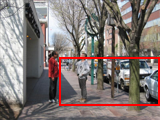
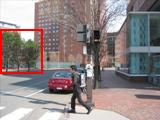
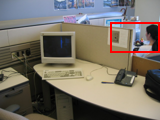
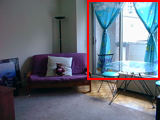
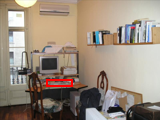


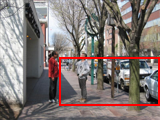
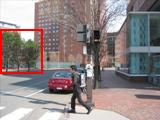
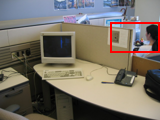
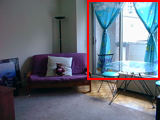
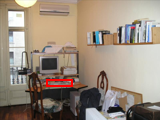

In [6]:
show("visual_genome")


In [7]:
# RefCOCOg: expression that points at one object using its surroundings
if not already("refcocog", 30):
    pf = pq.ParquetFile(fetch(
        "https://huggingface.co/datasets/lmms-lab/RefCOCOg/resolve/main/data/val-00000-of-00003.parquet",
        CACHE / "refcocog_val.parquet",
    ))
    saved, seen = [], set()
    for batch in pf.iter_batches(batch_size=32):
        for row in batch.to_pylist():
            name = row["image"]["path"]
            if name in seen:
                continue
            answers = row["answer"] or []
            hits = [a for a in answers if any(h in a.lower() for h in (" of the ", " next to ", " in front ", " behind ", " on the ", " beside ", " near "))]
            text = max(hits or answers, key=len)
            blob = row["image"]["bytes"]
            if not is_image(blob):
                continue
            seen.add(name)
            saved.append((name, blob, {"text": text, "boxes": [{"bbox": row["bbox"]}]}))
            if len(saved) == 30:
                break
        if len(saved) == 30:
            break
    save("refcocog", saved)


refcocog: already have 30



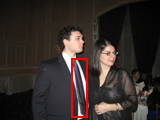
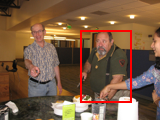
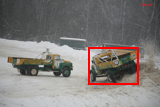
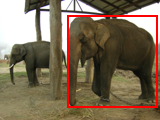
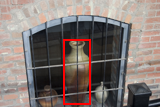


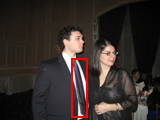
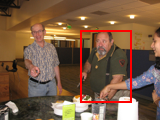
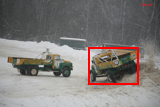
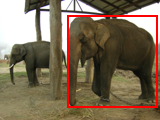
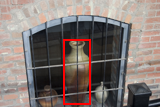

In [8]:
show("refcocog")


In [9]:
# VisualNews: news photo + caption (person at an event or a place)
if not already("visualnews", 30):
    captions = {
        row["image_path"].lstrip("./"): row["caption"]
        for row in json.loads(fetch(
            "https://huggingface.co/datasets/twelcone/VisualNews/resolve/main/data.json",
            CACHE / "visualnews_data.json",
        ).read_text())
    }
    resp = stream("https://www.cs.rice.edu/~vo9/visualnews/origin.tar")
    resp.raw.decode_content = True
    saved, tf = [], tarfile.open(fileobj=resp.raw, mode="r|")
    try:
        for member in tf:
            if not member.isfile() or not member.name.lower().endswith(".jpg"):
                continue
            rel = member.name.split("origin/", 1)[-1]
            blob = tf.extractfile(member).read()
            text = captions.get(rel)
            if not text or not is_image(blob):
                continue
            saved.append((rel.replace("/", "_"), blob, {"text": text}))
            if len(saved) == 30:
                break
    finally:
        try:
            tf.close()
        except Exception:
            pass
        resp.close()
    save("visualnews", saved)


visualnews: already have 30



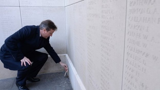
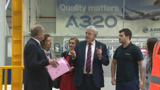
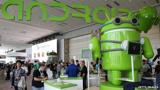
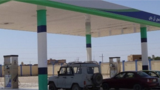
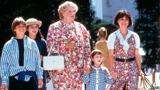


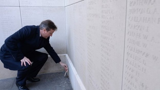
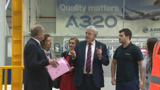
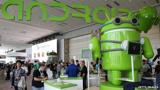
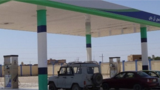
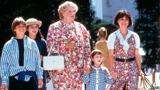

In [10]:
show("visualnews")


In [11]:
# Task 3: object with background, from Visual Genome
hints = (" in front ", " next to ", " behind ", " beside ", " along ", " infront ", " on the ", " on a ", " with a ", " near ", " above ", " under ")
rows = json.loads((ROOT / "visual_genome" / "gt.json").read_text())
out = []
for row in rows:
    text, low = row["text"], row["text"].lower()
    cut = min((low.find(h) for h in hints if low.find(h) > 0), default=-1)
    subject, background = (text[:cut].strip(" ,."), text[cut:].strip(" ,.")) if cut > 0 else (text.strip(), "")
    out.append({**row, "type": "object_with_background", "subject": subject, "background": background,
                "text": f"{subject} | {background}" if background else subject})
dest = ROOT / "visual_genome_task3"
(dest / "images").mkdir(parents=True, exist_ok=True)
for img in (ROOT / "visual_genome" / "images").iterdir():
    link = dest / "images" / img.name
    if not link.exists():
        link.symlink_to(img.resolve())
(dest / "gt.json").write_text(json.dumps(out, indent=2))
print(len(out), "object_with_background")


30 object_with_background



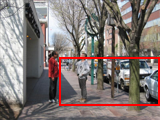
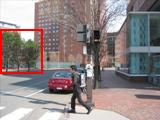
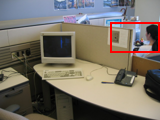
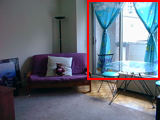
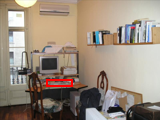


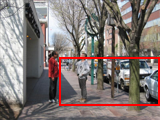
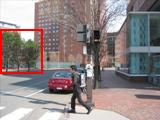
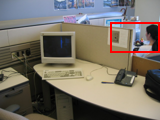
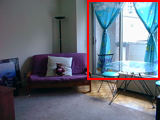
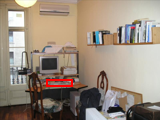

In [12]:
show("visual_genome_task3")


In [13]:
# Task 3: object with background, from RefCOCOg
hints = (" in front ", " next to ", " behind ", " beside ", " of the ", " on the ", " with a ", " with the ", " near ", " by a ")
rows = json.loads((ROOT / "refcocog" / "gt.json").read_text())
out = []
for row in rows:
    text, low = row["text"], row["text"].lower()
    cut = min((low.find(h) for h in hints if low.find(h) > 0), default=-1)
    subject, background = (text[:cut].strip(" ,."), text[cut:].strip(" ,.")) if cut > 0 else (text.strip(), "")
    out.append({**row, "type": "object_with_background", "subject": subject, "background": background,
                "text": f"{subject} | {background}" if background else subject})
dest = ROOT / "refcocog_task3"
(dest / "images").mkdir(parents=True, exist_ok=True)
for img in (ROOT / "refcocog" / "images").iterdir():
    link = dest / "images" / img.name
    if not link.exists():
        link.symlink_to(img.resolve())
(dest / "gt.json").write_text(json.dumps(out, indent=2))
print(len(out), "object_with_background")


30 object_with_background



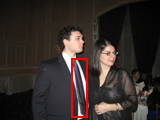
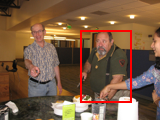
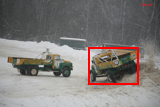
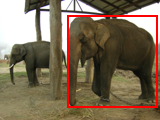
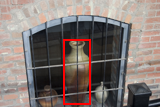


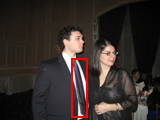
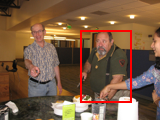
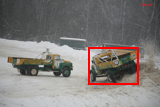
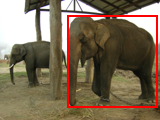
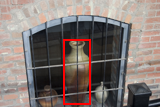

In [14]:
show("refcocog_task3")


In [15]:
# Task 3: famous person in the foreground, from the VisualNews caption
import re
name_re = re.compile(r"^((?:Mr|Mrs|Ms|Dr|Prof)\s+[A-Z][a-z]+|[A-Z][a-z]+(?:\s+[A-Z][a-z]+){1,2})\b")
title_re = re.compile(r"\b((?:Mr|Mrs|Ms|Dr|Prof)\s+[A-Z][a-z]+)\b")
place_re = re.compile(r"\b(?:at|in|near|outside|visits|from)\s+(?:the\s+)?([A-Z][A-Za-z' ]{2,40}?)(?=\s+(?:which|to|and|for|with|who|was|is|has|in)\b|[,.]|$)")
events = ("wedding", "memorial", "campaign", "ceremony", "debate", "protest")
out = []
for row in json.loads((ROOT / "visualnews" / "gt.json").read_text()):
    text = row["text"]
    m = name_re.match(text) or title_re.search(text)
    if not m or m.group(1).split()[0] in {"The", "A", "An"}:
        continue
    person = m.group(1)
    found = place_re.search(text)
    context = found.group(1).strip() if found else ""
    event = next((w for w in events if w in text.lower()), "")
    kind = "people_at_event" if event else ("people_at_location" if context else "person")
    if event and not context:
        context = event
    out.append({**row, "type": kind, "person": person, "context": context,
                "text": f"{person} at {context}" if context else person})
dest = ROOT / "visualnews_task3"
(dest / "images").mkdir(parents=True, exist_ok=True)
for img in (ROOT / "visualnews" / "images").iterdir():
    link = dest / "images" / img.name
    if not link.exists():
        link.symlink_to(img.resolve())
(dest / "gt.json").write_text(json.dumps(out, indent=2))
print(len(out), "with a person in the foreground")


12 with a person in the foreground



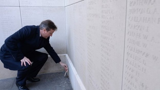
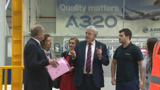
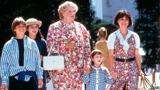
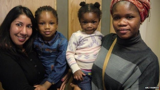
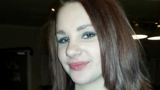


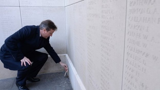
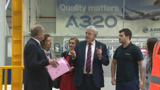
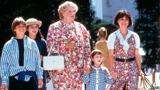
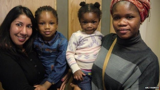
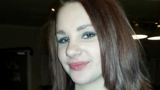

In [16]:
show("visualnews_task3")


In [17]:
# ABO-Edit: 30 lifestyle photos, product in a real room
if not already("abo_edit", 30):
    import pyarrow.ipc as ipc
    path = fetch(
        "https://huggingface.co/datasets/amazon/ABO-Edit/resolve/main/train/data-00000-of-00035.arrow",
        CACHE / "abo_edit_00000.arrow",
    )
    saved, seen = [], set()
    for batch in ipc.open_stream(path):
        for row in batch.to_pylist():
            pid, blob = row["x_source_image_id"], row["xsource_image"]["bytes"]
            if pid in seen or not is_image(blob):
                continue
            seen.add(pid)
            ext = ".png" if blob[:8] == b"\x89PNG\r\n\x1a\n" else ".jpg"
            saved.append((f"{pid}{ext}", blob, {
                "type": "object_with_background",
                "subject": row["object_description"] or row["product_type"],
                "text": row["object_description"] or row["product_title"],
            }))
            if len(saved) == 30:
                break
        if len(saved) == 30:
            break
    save("abo_edit", saved)


abo_edit: already have 30



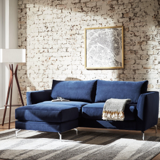
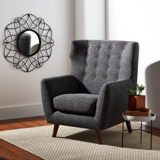
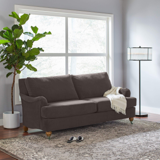
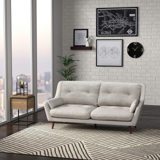
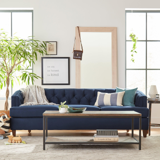


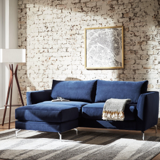
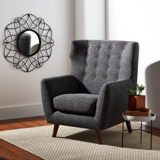
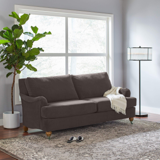
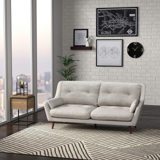
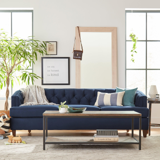

In [18]:
show("abo_edit")


In [19]:
# AVA: 30 short clips and one frame each, largest person box
if not already("ava", 30):
    import re, subprocess
    from collections import defaultdict
    names = fetch(
        "https://s3.amazonaws.com/ava-dataset/annotations/ava_file_names_trainval_v2.1.txt",
        CACHE / "ava_names.txt",
    ).read_text().split()
    files = {Path(name).stem: name for name in names}
    with zipfile.ZipFile(fetch("https://s3.amazonaws.com/ava-dataset/annotations/ava_v2.2.zip", CACHE / "ava_v2.2.zip")) as z:
        actions = {int(i): n for n, i in re.findall(r'name: "(.*)"\n  label_id: (\d+)', z.read("ava_action_list_v2.2.pbtxt").decode())}
        lines = z.read("ava_train_v2.2.csv").decode().splitlines()
    picks = defaultdict(list)
    for line in lines:
        vid, ts, x1, y1, x2, y2, act, pid = line.split(",")
        picks[vid].append((int(ts), float(x1), float(y1), float(x2), float(y2), int(act), pid))
    saved, videos = [], ROOT / "ava" / "videos"
    videos.mkdir(parents=True, exist_ok=True)
    for vid, anns in picks.items():
        if vid not in files:
            continue
        ts = anns[0][0]
        group = [a for a in anns if a[0] == ts]
        best = max(group, key=lambda a: (a[3] - a[1]) * (a[4] - a[2]))
        acts = ", ".join(sorted({actions.get(a[5], str(a[5])) for a in group if a[6] == best[6]}))
        full = CACHE / "ava_full" / files[vid]
        full.parent.mkdir(parents=True, exist_ok=True)
        if not full.exists() or full.stat().st_size == 0:
            tmp = full.with_suffix(full.suffix + ".part")
            resp = stream(f"https://s3.amazonaws.com/ava-dataset/trainval/{files[vid]}", timeout=600)
            with tmp.open("wb") as f:
                for chunk in resp.iter_content(1 << 20):
                    if chunk:
                        f.write(chunk)
            resp.close()
            tmp.replace(full)
        clip, frame = videos / f"{vid}.mp4", ROOT / "ava" / "images" / f"{vid}.jpg"
        frame.parent.mkdir(parents=True, exist_ok=True)
        try:
            subprocess.run(["ffmpeg", "-y", "-ss", str(ts), "-i", str(full), "-t", "4", "-an", "-c:v", "libx264", "-preset", "ultrafast", str(clip)], check=True, capture_output=True)
            subprocess.run(["ffmpeg", "-y", "-ss", str(ts), "-i", str(full), "-frames:v", "1", "-update", "1", str(frame)], check=True, capture_output=True)
        except Exception as e:
            print("skip", vid, type(e).__name__)
            continue
        full.unlink()
        w, h = Image.open(frame).size
        x1, y1, x2, y2 = best[1:5]
        saved.append((frame.name, frame.read_bytes(), {
            "type": "person", "video": clip.name, "text": f"person {acts}",
            "boxes": [{"bbox": [x1 * w, y1 * h, (x2 - x1) * w, (y2 - y1) * h]}],
        }))
        print(len(saved), vid, flush=True)
        if len(saved) == 30:
            break
    save("ava", saved)


ava: already have 30



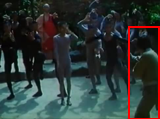
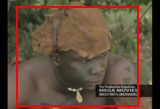
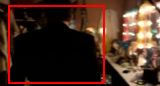
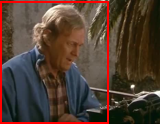
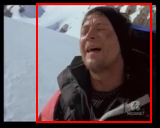


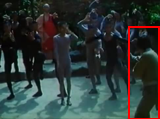
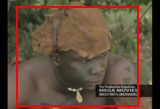
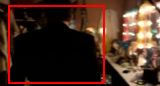
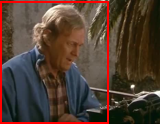
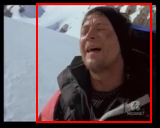

In [20]:
show("ava")


In [22]:
play("ava")


person martial art, watch (a person)


person sit, talk to (e.g., self, a person, a group)


person walk, watch (a person)


person stand, talk to (e.g., self, a person, a group), touch (an object)


person carry/hold (an object), stand, talk to (e.g., self, a person, a group), watch (a person)


In [28]:
# C-SPAN: 30 public Archive.org clips with strong person@place/event labels
if not already("cspan", 30):
    import subprocess, re
    from concurrent.futures import ThreadPoolExecutor, as_completed
    people = (("president biden","Joe Biden"),("president trump","Donald Trump"),("president obama","Barack Obama"),
              ("vice president harris","Kamala Harris"),("vice president pence","Mike Pence"),("speaker pelosi","Nancy Pelosi"),
              ("pelosi","Nancy Pelosi"),("pence","Mike Pence"),("harris","Kamala Harris"),("clinton","Hillary Clinton"),
              ("sanders","Bernie Sanders"),("biden","Joe Biden"),("trump","Donald Trump"),("obama","Barack Obama"))
    venues = [("oval office","Oval Office",True),("joint base andrews","Joint Base Andrews",True),("capitol rotunda","Capitol Rotunda",True),
              ("pentagon","Pentagon",True),("national republican congressional","NRCC",False),("campaign announcement","campaign announcement",False),
              ("republican national convention","Republican National Convention",False),("democratic national convention","Democratic National Convention",False),
              ("state of the union","State of the Union",False)]
    def parse(title):
        low = title.lower()
        if ("cspan" not in low and "c-span" not in low) or "88022" in low: return None
        if re.search(r"\b(killing|war|troops|sanctions|airstrike).{0,40}\bin\b", low): return None  # topic, not venue
        person = next((n for k,n in people if k in low), "")
        if not person: return None
        for key, lab, is_place in venues:
            if key in low: return person, lab, is_place
        if re.search(r"\bwhite house\b", low) and "road to the white house" not in low: return person, "White House", True
        m = re.search(r"(?:Rally|Remarks|Speech|Address)\s+(?:In|At)\s+(?:the\s+)?([A-Z][^:\[\(|]{2,40})", title)
        if m:
            place = re.split(r"\s{2,}|\.\.\.|\[|,?\s+on\s+", m.group(1))[0].strip(" .,")
            if place.lower() in {"iraq","remarks","speech","address","c-span","cspan"}: return None
            if 2 < len(place) < 45 and '"' not in place: return person, place, True
        return None
    q = '(title:CSPAN OR title:"C-SPAN" OR title:cspan OR identifier:cspan*) AND (Trump OR Biden OR Obama OR Harris OR Pence OR Pelosi) AND mediatype:movies AND item_size:[100000 TO 100000000]'
    docs, seen = [], set()
    for page in range(1, 20):
        batch = S.get("https://archive.org/advancedsearch.php", params={"q": q, "fl[]": ["identifier","title","item_size"], "rows": 50, "page": page, "sort[]": "item_size asc", "output": "json"}, timeout=60).json()["response"]["docs"]
        if not batch: break
        for d in batch:
            if d["identifier"] not in seen: seen.add(d["identifier"]); docs.append(d)
    cands = [{**d, **dict(zip(("person","context","is_place"), parse(d["title"])))} for d in docs if parse(d["title"])]
    def probe(d):
        try:
            meta = S.get(f"https://archive.org/metadata/{d['identifier']}", timeout=20).json()
            mp4s = [f for f in meta.get("files") or [] if str(f.get("name","")).lower().endswith(".mp4") and 50_000 < int(f.get("size") or 0) < 90_000_000]
            if not mp4s: return None
            src = min(mp4s, key=lambda f: int(f["size"]))
            url = "https://archive.org/download/{}/{}".format(d["identifier"], requests.utils.quote(src["name"]))
            return {**d, "url": url} if S.head(url, timeout=15, allow_redirects=True).status_code == 200 else None
        except Exception: return None
    opens = []
    with ThreadPoolExecutor(16) as ex:
        for fut in as_completed(ex.submit(probe, d) for d in cands):
            if (r := fut.result()): opens.append(r)
    videos = ROOT / "cspan" / "videos"; videos.mkdir(parents=True, exist_ok=True)
    saved = []
    for d in opens:
        if len(saved) == 30: break
        try: blob = read_url(d["url"])
        except Exception: continue
        raw, clip = videos / "src.mp4", videos / f"{len(saved)}.mp4"
        frame = ROOT / "cspan" / "images" / f"{len(saved)}.jpg"; frame.parent.mkdir(parents=True, exist_ok=True)
        raw.write_bytes(blob)
        subprocess.run(["ffmpeg","-y","-i",str(raw),"-t","6","-vf","scale=320:-2","-an","-c:v","libx264","-preset","ultrafast","-crf","32",str(clip)], check=True, capture_output=True)
        subprocess.run(["ffmpeg","-y","-ss","1","-i",str(clip),"-frames:v","1","-update","1",str(frame)], check=True, capture_output=True)
        raw.unlink()
        saved.append((frame.name, frame.read_bytes(), {"type": "people_at_location" if d["is_place"] else "people_at_event", "person": d["person"], "context": d["context"], "title": d["title"], "video": clip.name, "text": f"{d['person']} at {d['context']}"}))
        print(len(saved), saved[-1][2]["text"], flush=True)
    save("cspan", saved)
print("cspan strong task3:", len(json.loads((ROOT/"cspan"/"gt.json").read_text())), "images+videos")


cspan: already have 4
strong task3: 4 images+videos



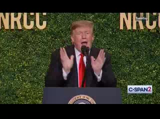
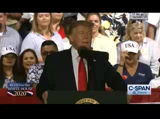
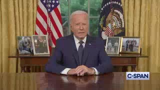
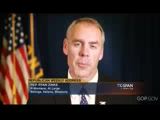


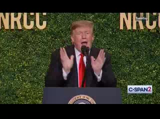
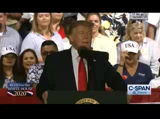
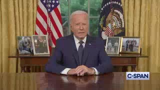
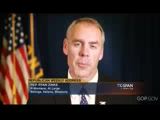

In [29]:
show("cspan")


In [30]:
play("cspan")


Donald Trump at NRCC


Donald Trump at Panama City


Joe Biden at Oval Office


Donald Trump at campaign announcement


In [ ]:
# Task3 person@place/event: Obama×10, Biden×10, Cruise/Pitt/Affleck×2 (yt-dlp local → 6s@320)
import subprocess, tempfile, shutil
CLIPS = {
    "obama": ("Barack Obama", [
        ("6IoVSbjmTZs", "White House Correspondents' Dinner", False), ("eWynt87PaJ0", "DNC Convention", False),
        ("OUvJdPhvdYI", "Antalya", True), ("wEw3H0C-Lj8", "Cuba", True), ("B_889oBKkNU", "Cairo", True),
        ("kKQV9bEcV28", "Democratic National Convention", False), ("vdoi2aTf9W8", "United Nations", True),
        ("OJJDqsW_kac", "Obama Presidential Center", True), ("AqEsahwoxb8", "UN General Assembly", True),
        ("n9mzJhvC-8E", "White House Correspondents' Dinner", False),
    ]),
    "biden": ("Joe Biden", [
        ("EhL0Z51OiBY", "Oval Office", True), ("Tqqc-UFcSlU", "Oval Office", True),
        ("Cbk7elR9I_I", "White House Correspondents' Dinner", False), ("UBwePA2hRho", "Buffalo", True),
        ("peWlRgDqUz4", "State of the Union", False), ("ZwvbQR887W0", "Presidential Inauguration", False),
        ("xn_8UQ1W6_c", "campaign kickoff", False), ("CdzGHBUEMY8", "White House Correspondents' Dinner", False),
        ("bDZ1H4ABmiU", "White House Correspondents' Dinner", False), ("Wu-8s396n54", "Oval Office", True),
    ]),
    "tom_cruise": ("Tom Cruise", [("ow219idh6LU", "Rome premiere", False), ("A7q1yOZoDGk", "London premiere", False)]),
    "brad_pitt": ("Brad Pitt", [("StoEJUgtQA0", "Venice Film Festival", False), ("1dzbJqq66Ac", "Mr. & Mrs. Smith premiere", False)]),
    "ben_affleck": ("Ben Affleck", [("D_8Ef7oRckc", "Oscars", False), ("k4lktbyYdE8", "Oscars", False)]),
}
# Note: some fills may come from Archive.org mirrors if a YouTube id fails; data/* already populated.


def yt_clip(yt_id, dest):
    tmp = Path(tempfile.mkdtemp(prefix="yt_")); dest = Path(dest)
    try:
        subprocess.run(["yt-dlp", "--no-update", "-f", "134/160/18/best[height<=360]/best", "--no-playlist",
                        "-o", str(tmp / "src.%(ext)s"), f"https://www.youtube.com/watch?v={yt_id}"], check=True, capture_output=True)
        src = next(tmp.glob("src.*"))
        for ss in ("20", "5", "0"):
            r = subprocess.run(["ffmpeg", "-y", "-ss", ss, "-i", str(src), "-t", "6", "-vf", "scale=320:-2", "-an",
                                "-c:v", "libx264", "-preset", "ultrafast", "-crf", "32", str(dest)], capture_output=True)
            if r.returncode == 0 and dest.stat().st_size > 5000: return
        raise RuntimeError(yt_id)
    finally:
        shutil.rmtree(tmp, ignore_errors=True)

for name, (person, items) in CLIPS.items():
    if already(name, len(items)): continue
    vids = ROOT / name / "videos"; vids.mkdir(parents=True, exist_ok=True); saved = []
    for i, (yt_id, context, is_place) in enumerate(items):
        clip, frame = vids / f"{i}.mp4", ROOT / name / "images" / f"{i}.jpg"
        frame.parent.mkdir(parents=True, exist_ok=True)
        print(len(saved) + 1, f"{person} at {context}", flush=True)
        yt_clip(yt_id, clip)
        subprocess.run(["ffmpeg", "-y", "-ss", "1", "-i", str(clip), "-frames:v", "1", "-update", "1", str(frame)], check=True, capture_output=True)
        saved.append((frame.name, frame.read_bytes(), {"type": "people_at_location" if is_place else "people_at_event",
            "person": person, "context": context, "title": f"{person} at {context}", "video": clip.name,
            "text": f"{person} at {context}", "source": f"https://www.youtube.com/watch?v={yt_id}"}))
    save(name, saved)


In [ ]:
for name in ("obama", "biden", "tom_cruise", "brad_pitt", "ben_affleck"):
    show(name)
